In [6]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

#Quitamos casos atípicos
df = pd.read_csv("../data/processed/listings_clean.csv")
df = df[(df["bedrooms"] <= 6) & (df["accommodates"] <= 10)]

modelo = smf.ols(
    "log_price ~ C(room_type) + C(neighbourhood_cleansed) + accommodates + bedrooms + review_scores_rating + availability_365",
    data=df
).fit()

print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.476
Model:                            OLS   Adj. R-squared:                  0.475
Method:                 Least Squares   F-statistic:                     967.0
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:45:54   Log-Likelihood:                -13429.
No. Observations:               23463   AIC:                         2.690e+04
Df Residuals:                   23440   BIC:                         2.709e+04
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                                                          coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------

In [7]:
coefs = modelo.params.drop("Intercept")
efecto = ((np.exp(coefs) - 1) * 100).round(1)
tabla = pd.DataFrame({"efecto_%_en_precio": efecto, "p_value": modelo.pvalues.drop("Intercept").round(4)})
tabla.sort_values("efecto_%_en_precio", ascending=False)

,efecto_%_en_precio,p_value
C(neighbourhood_cleansed)[T.Miguel Hidalgo],74.6,0.0000
C(neighbourhood_cleansed)[T.Cuajimalpa de Morelos],61.7,0.0000
C(neighbourhood_cleansed)[T.Cuauhtémoc],58.8,0.0000
C(neighbourhood_cleansed)[T.Álvaro Obregón],41.2,0.0000
C(neighbourhood_cleansed)[T.Coyoacán],30.6,0.0000
C(neighbourhood_cleansed)[T.Benito Juárez],29.1,0.0000
C(neighbourhood_cleansed)[T.La Magdalena Contreras],26.6,0.0000
C(neighbourhood_cleansed)[T.Tlalpan],20.9,0.0000
bedrooms,14.7,0.0000
C(neighbourhood_cleansed)[T.Iztacalco],12.6,0.0001


R2: 0.469
Error promedio (MXN): 578


<function matplotlib.pyplot.show(close=None, block=None)>

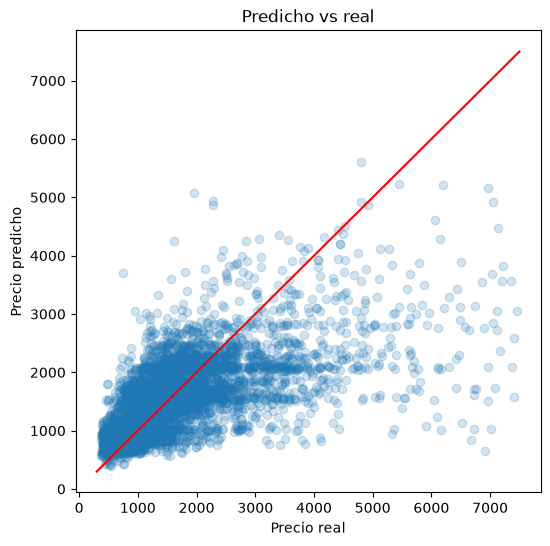

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt

X = pd.get_dummies(
    df[["room_type", "neighbourhood_cleansed", "accommodates", "bedrooms", "review_scores_rating", "availability_365"]],
    drop_first=True
)
y = df["log_price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
lr = LinearRegression().fit(X_train, y_train)
pred = lr.predict(X_test)

print("R2:", round(r2_score(y_test, pred), 3))
print("Error promedio (MXN):", round(mean_absolute_error(np.exp(y_test), np.exp(pred))))

plt.figure(figsize=(6, 6))
plt.scatter(np.exp(y_test), np.exp(pred), alpha=0.2)
plt.plot([300, 7500], [300, 7500], color="red")
plt.xlabel("Precio real")
plt.ylabel("Precio predicho")
plt.title("Predicho vs real")
plt.show()

In [11]:
print("R2:", round(r2_score(y_test, pred), 3))
print("Error promedio (MXN):", round(mean_absolute_error(np.exp(y_test), np.exp(pred))))
print("Alcaldía de referencia:", sorted(df["neighbourhood_cleansed"].unique())[0])

R2: 0.469
Error promedio (MXN): 578
Alcaldía de referencia: Azcapotzalco
